# Using EPIG to select experiments

Expected Predictive Information Gain (EPIG) is a target-aware acquisition method for active learning. It scores candidate reactions according to the information their outcomes are expected to provide about predictions on a specified target set.

This notebook shows how to score and select reactions and how to run an active learning simulation. We demonstrate EPIG using Wittig reaction data in two examples: a random split and a cluster split.

EPIG is compared with BALD, which scores candidates by their expected information gain about the model parameters, and Random, which selects candidates at random. Neither is target-aware.

Run the notebook using the environment specified in the repository's `environment.yml`.

In [1]:
import sys
from collections import namedtuple
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from sklearn.cluster import AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler

REPO = Path.cwd()
if REPO.name == "notebooks":
    REPO = REPO.parent
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

from epig_al import acquisition_scores, select_batch, ActiveLearner
from epig_al.acquisition import AcquireManager

# Strategy names and colours as used for the manuscript figures; the same values
# are recorded in scripts/build_si_learning_curves.py.
METHOD_NAMES = {"epig": "EPIG", "bald": "BALD", "indv_nn": "Indiv. NN",
                "nn": "NN", "random": "Random"}
METHOD_COLORS = {"EPIG": "#117733", "BALD": "#4477AA", "Indiv. NN": "#AA3377",
                 "NN": "#EE7733", "Random": "#707070"}
METHOD_MARKERS = {"EPIG": "o", "BALD": "s", "Random": "^"}
TARGET_COLOR = "#E69F00"

print("epig_al ready — API: acquisition_scores, select_batch, ActiveLearner")

epig_al ready — API: acquisition_scores, select_batch, ActiveLearner


## 1. Preparing the data

EPIG requires three groups of reactions:

- **Training set:** Reactions with measured outcomes (`X_train`, `y_train`).
- **Acquisition pool:** Candidate reactions available for selection (`X_pool`).
- **Target set:** Reactions for which accurate predictions are desired (`X_target`).

We use 734 Wittig reactions from Vedejs and Peterson's *Stereochemistry and Mechanism in the Wittig Reaction*, represented by 119 descriptors, with reported Z selectivity as the prediction outcome. The descriptors are standardized; a two-dimensional principal component analysis (PCA) projection is used only for plotting.

Each example defines a target set. `make_split` holds it out and divides the remaining reactions into an initial training set of 24 reactions and an acquisition pool.

In [2]:
df = pd.read_csv(REPO / "data/Wittig/wittig_literature_f119.csv")

# Leading metadata columns; everything after them is the F119 descriptor block.
METADATA = ["record_id", "source_table", "source_entry", "condition_index",
            "z_selectivity_percent", "temperature_c", "solvent_reported",
            "solvent_standardized", "solvent_smiles", "aldehyde_smiles",
            "ylide_smiles", "base_smiles", "in_situ", "rxn_smiles"]
features = [c for c in df.columns if c not in METADATA]
assert len(features) == 119, f"expected the 119 F119 descriptors, got {len(features)}"
X_raw = df[features].to_numpy(float)
y = df["z_selectivity_percent"].to_numpy(float)   # response: reported Z selectivity (%)

# Use one standardized feature matrix for modeling and clustering; PCA is for plotting only.
X = StandardScaler().fit_transform(X_raw)
P = PCA(n_components=2, random_state=0).fit_transform(X)

Split = namedtuple("Split", ["labeled", "pool", "target"])


def make_split(target, seed=0, n_labeled=24):
    """Hold out the target reactions and shuffle the rest into a training set and a pool."""
    target = np.sort(target)
    rest = np.random.default_rng(seed).permutation(np.setdiff1d(np.arange(len(y)), target))
    return Split(labeled=rest[:n_labeled], pool=rest[n_labeled:], target=target)


print(f"reactions   : {len(y)}")
print(f"descriptors : {X.shape[1]}")

reactions   : 734
descriptors : 119


## 2. Example 1: Random split

We randomly select 142 reactions as the target set.

In [3]:
random_split = make_split(np.random.default_rng(1).choice(len(y), size=142, replace=False))
print({name: len(rows) for name, rows in random_split._asdict().items()})

{'labeled': 24, 'pool': 568, 'target': 142}


### Scoring and selecting experiments

We first fit a random forest to the initial training set. EPIG uses predictions from the individual trees to estimate uncertainty and score each candidate according to its expected predictive information about the target set.

`acquisition_scores` returns a score for every candidate, while `select_batch` returns the indices of the eight highest-scoring candidates.

These eight reactions are selected from a single scoring of the pool; the model is not refitted between selections.

In [4]:
labeled, pool, target = random_split
model = RandomForestRegressor(n_estimators=300, random_state=0).fit(X[labeled], y[labeled])

scores = acquisition_scores(model, X[pool], X[target], X_train=X[labeled], y_train=y[labeled], metric="epig")

top = select_batch(model, X[pool], X[target], X_train=X[labeled], y_train=y[labeled], k=8, metric="epig")
print("EPIG selection, k = 8 (positions within the acquisition pool):", top.tolist())
pd.DataFrame({
    "dataset_row": [int(pool[i]) for i in top],
    "epig_score": scores[top].round(4),
    "reaction": df.loc[[int(pool[i]) for i in top], "rxn_smiles"].values,
}).reset_index(drop=True)

EPIG selection, k = 8 (positions within the acquisition pool): [564, 388, 197, 336, 510, 431, 97, 6]


,dataset_row,epig_score,reaction
0,34,0.0370,O=Cc1ccccc1.CCCC=P(c1ccccc1)(c1ccccc1)c1ccccc1...
1,33,0.0370,O=Cc1ccccc1.CCCC=P(c1ccccc1)(c1ccccc1)c1ccccc1...
2,29,0.0368,O=Cc1ccccc1.CCC=P(c1ccccc1)(c1ccccc1)c1ccccc1....
3,30,0.0368,O=Cc1ccccc1.CCC=P(c1ccccc1)(c1ccccc1)c1ccccc1....
4,27,0.0368,O=Cc1ccccc1.CCC=P(c1ccccc1)(c1ccccc1)c1ccccc1....
5,28,0.0368,O=Cc1ccccc1.CCC=P(c1ccccc1)(c1ccccc1)c1ccccc1....
6,32,0.0363,O=Cc1ccccc1.CCC=P(c1ccccc1)(c1ccccc1)c1ccccc1....
7,31,0.0363,O=Cc1ccccc1.CCC=P(c1ccccc1)(c1ccccc1)c1ccccc1....


### Running the acquisition loop

`ActiveLearner` repeatedly fits a model, scores the remaining candidates, acquires new reactions, and refits the model. Because the dataset is fully measured, the simulation can reveal the known outcomes of selected reactions; `run` returns the target-set score after each acquisition round.

Here, eight reactions are acquired per round for eight acquisition rounds, in five repetitions with different initial training sets. In each repetition, all methods use the same initial training set of 24 reactions, acquisition pool, and random-forest seed. Lines show the mean over the repetitions, and bands span the lowest and highest repetition; the dashed line marks $R^2 = 0$.

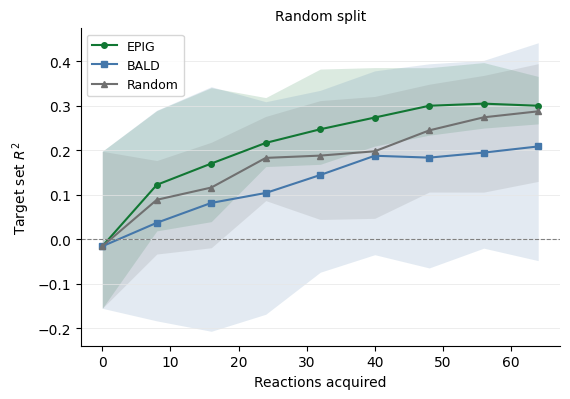

In [5]:
REPETITIONS = range(5)   # one initial training set per repetition; every method uses the same ones


def learning_curves(target, methods=("epig", "bald", "random"), repetitions=REPETITIONS,
                    n_rounds=8, batch=8):
    """Target-set R^2 after each round, one column per (method, repetition)."""
    curves = {}
    for m in methods:
        for rep in repetitions:
            AcquireManager.set_seed(rep)   # fixed per repetition, so Random is reproducible
            labeled, pool, _ = make_split(target, seed=rep)   # same initial training set for every method
            # 150 trees per round (300 in the single scoring above) keep the simulation fast.
            al = ActiveLearner(lambda rep=rep: RandomForestRegressor(n_estimators=150, random_state=rep),
                               metric=m, batch_size=batch)
            t = al.run(X, y, labeled=labeled.tolist(), pool=pool.tolist(), target=target.tolist(),
                       n_rounds=n_rounds)
            curves[(METHOD_NAMES[m], rep)] = t.set_index("n_acquired")["target_score"]
    return pd.DataFrame(curves)


def plot_learning_curves(curves, title):
    fig, ax = plt.subplots(figsize=(5.8, 4.1))
    for name in curves.columns.unique(level=0):
        c = curves[name]
        ax.fill_between(c.index, c.min(axis=1), c.max(axis=1), color=METHOD_COLORS[name],
                        alpha=0.15, lw=0)
        ax.plot(c.index, c.mean(axis=1), marker=METHOD_MARKERS[name], ms=4, label=name,
                color=METHOD_COLORS[name])
    ax.axhline(0, color="0.5", lw=0.8, ls="--")
    ax.set_xlabel("Reactions acquired")
    ax.set_ylabel(r"Target set $R^2$")
    ax.set_title(title, fontsize=10)
    ax.grid(axis="y", color="0.9", linewidth=0.5)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(fontsize=9)
    plt.tight_layout(); plt.show()


random_curves = learning_curves(random_split.target)
plot_learning_curves(random_curves, "Random split")

## 3. Example 2: Cluster split

We group the reactions into eight clusters by agglomerative clustering with Ward linkage and Euclidean distances on all 119 standardized descriptors, and hold out cluster 0 (207 reactions) as the target set. The clustering uses the full descriptor space rather than the PCA coordinates, so the cluster need not look compact in the two-dimensional view.

In [6]:
TARGET_CLUSTER = 0
# Ward linkage (Euclidean distances) on the full standardized descriptor matrix.
clusters = AgglomerativeClustering(n_clusters=8, linkage="ward").fit_predict(X)
print("cluster sizes:", np.bincount(clusters).tolist())

cluster_split = make_split(np.where(clusters == TARGET_CLUSTER)[0])
print({name: len(rows) for name, rows in cluster_split._asdict().items()})
rest = np.concatenate([cluster_split.labeled, cluster_split.pool])
print(f"mean Z selectivity: target set {y[cluster_split.target].mean():.0f} %, "
      f"other reactions {y[rest].mean():.0f} %")

cluster sizes: [207, 16, 69, 114, 4, 238, 35, 51]
{'labeled': 24, 'pool': 503, 'target': 207}
mean Z selectivity: target set 28 %, other reactions 49 %


### Visualizing the selected reactions

The first two principal components show the initial training set, acquisition pool, target set, and the 12 candidates that each method selects from one model fit. Acquisition scores are calculated using the full descriptor representation; PCA is used only for visualization.

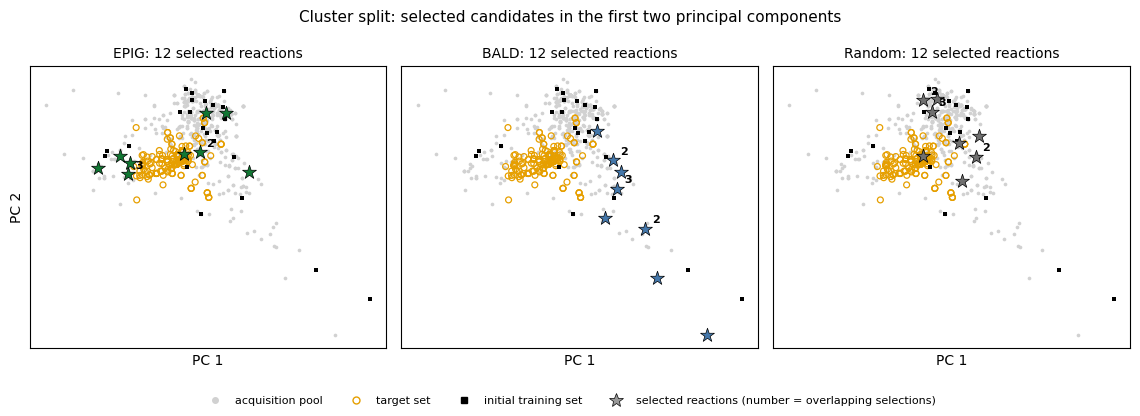

In [7]:
labeled, pool, target = cluster_split
model = RandomForestRegressor(n_estimators=300, random_state=0).fit(X[labeled], y[labeled])
# Random acquisition draws from AcquireManager's module-level generator; seed it
# so the Random panel is reproducible. EPIG and BALD do not draw from it.
AcquireManager.set_seed(0)
picks = {m: pool[select_batch(model, X[pool], X[target], X_train=X[labeled],
                              y_train=y[labeled], k=12, metric=m)]
         for m in ("epig", "bald", "random")}


def overlap_groups(rows, radius):
    """Group selected reactions whose PCA positions are closer than `radius`."""
    groups = []
    for i in rows:
        for g in groups:
            if np.linalg.norm(P[i] - P[g[0]]) < radius:
                g.append(i)
                break
        else:
            groups.append([i])
    return groups


radius = 0.03 * np.ptp(P, axis=0).max()   # stars closer than this overlap on screen
fig, axes = plt.subplots(1, len(picks), figsize=(11.5, 4.1), sharex=True, sharey=True)
for ax, (m, rows) in zip(axes, picks.items()):
    name = METHOD_NAMES[m]
    ax.scatter(P[pool, 0], P[pool, 1], s=7, c="0.82", lw=0)
    ax.scatter(P[target, 0], P[target, 1], s=18, facecolors="none", edgecolors=TARGET_COLOR, lw=0.9)
    ax.scatter(P[labeled, 0], P[labeled, 1], s=12, marker="s", c="k", lw=0)
    groups = overlap_groups(rows, radius)
    xy = np.array([P[g].mean(axis=0) for g in groups])
    ax.scatter(xy[:, 0], xy[:, 1], s=110, marker="*", c=METHOD_COLORS[name],
               edgecolor="k", lw=0.5, zorder=3)
    for (px, py), g in zip(xy, groups):
        if len(g) > 1:
            ax.annotate(str(len(g)), (px, py), xytext=(5, 4), textcoords="offset points",
                        fontsize=8, fontweight="bold")
    ax.set_title(f"{name}: {len(rows)} selected reactions", fontsize=10)
    ax.set_xlabel("PC 1"); ax.set_xticks([]); ax.set_yticks([])
axes[0].set_ylabel("PC 2")
handles = [Line2D([], [], ls="", marker="o", ms=4, mfc="0.82", mec="0.82", label="acquisition pool"),
           Line2D([], [], ls="", marker="o", ms=5, mfc="none", mec=TARGET_COLOR, label="target set"),
           Line2D([], [], ls="", marker="s", ms=4, mfc="k", mec="k", label="initial training set"),
           Line2D([], [], ls="", marker="*", ms=10, mfc="0.6", mec="k", mew=0.5,
                  label="selected reactions (number = overlapping selections)")]
fig.legend(handles=handles, loc="lower center", ncol=4, fontsize=8, frameon=False)
fig.suptitle("Cluster split: selected candidates in the first two principal components", fontsize=11)
plt.tight_layout(rect=(0, 0.07, 1, 1)); plt.show()

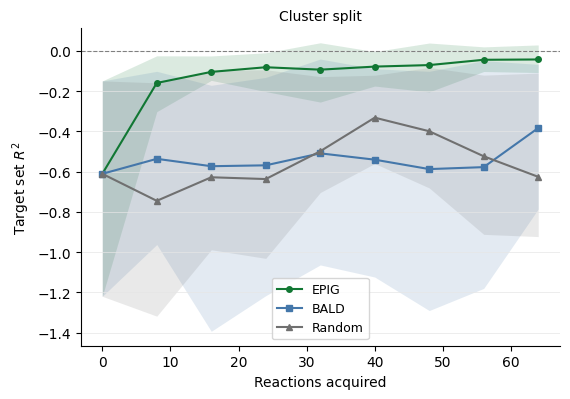

In [8]:
cluster_curves = learning_curves(cluster_split.target)
plot_learning_curves(cluster_curves, "Cluster split")

## 4. Using EPIG with your own data

Given a measured training set, an acquisition pool, and a target set, EPIG can be used to select the next experiments:

```python
from sklearn.ensemble import RandomForestRegressor
from epig_al import select_batch

model = RandomForestRegressor(n_estimators=300).fit(X_train, y_train)

next_indices = select_batch(
    model,
    X_pool,
    X_target,
    X_train=X_train,
    y_train=y_train,
    k=8,
    metric="epig",
)
```

The returned indices refer to rows of `X_pool`. After running the selected experiments, add their measured outcomes to the training data and refit the model before the next acquisition.

For a complete simulation on a fully measured dataset, use `ActiveLearner`. To obtain scores for every candidate rather than selecting a batch, use `acquisition_scores`.

EPIG and BALD require an ensemble model that provides predictions from individual members. Supported examples include random forests, extremely randomized trees, and bagged regressors.